# 04 — LSTM sequence model

**Purpose.** Train a 2-layer LSTM on 24-hour windows and compare it with the XGBoost baseline.

**Inputs.** Sequence arrays from notebook 02 (`dl_train`, `val`, `test`).

**Outputs.** `models/lstm.pt`, `results/predictions_lstm.csv`, `results/tables/metrics_lstm.csv`.


In [1]:
# Shared deep-learning setup: frozen splits, GPU if available, one global seed.
from pathlib import Path
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd().parent
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / ".mplconfig")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    SEED, set_seed, print_library_versions, ensure_dirs, save_fig,
    get_torch_device, WindowSequenceDataset, load_sequence_split,
    downsample_indices, predict_torch_model, count_parameters, file_size_mb,
    classification_metrics, choose_threshold_max_f1, early_detection_metrics,
    metrics_to_row, save_metrics_table, save_predictions,
    plot_confusion_heatmap, plot_roc_pr,
    permutation_importance_torch, time_step_importance_torch,
)
from src.torch_models import LSTMClassifier, train_sequence_model

set_seed(SEED)
print("SEED =", SEED)
print_library_versions()
PATHS = ensure_dirs(PROJECT_ROOT)
DEVICE = get_torch_device()
WINDOW = json.load(open(PATHS["processed"] / "sequence_config.json"))["window"]
print("WINDOW", WINDOW)


SEED = 42
python 3.9.6 (default, Oct 19 2026, 19:18:13)  [Clang 21.0.0 (clang-2100.4.1.1)]
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
xgboost      2.1.4
torch        2.8.0
shap         0.49.1
optuna       5.0.0
matplotlib   3.9.4
seaborn      0.13.2
Using device: cpu
WINDOW 24


## Class imbalance

`BCEWithLogitsLoss(pos_weight=n_neg/n_pos)` is computed from the **training windows we actually optimize on**. A `pos_weight` of 8 means a missed sepsis hour costs 8× a false alarm in the loss. Validation/test distributions are not re-balanced.


## Model-specific EDA: sequences, onset-aligned vitals, padding


mean fraction of a 24h window that would be padded at the *last* hour of the stay: 0.05624301250127046
patients shorter than 24h: 0.22105905071653623


/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "**Inputs.** Sequence arrays from notebook 02 (`dl_train`, `val`, `test`).\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:52: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "WINDOW = json.load(open(PATHS[\"processed\"] / \"sequence_config.json\"))[\"window\"]\n",


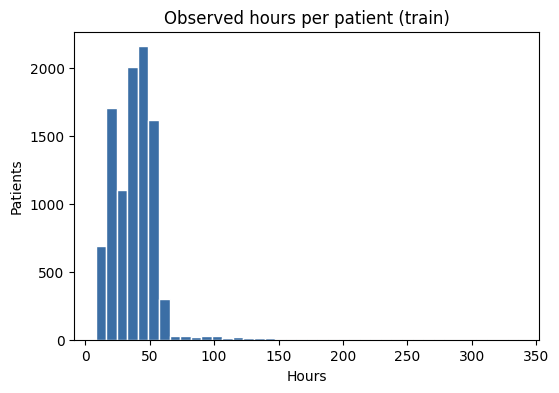

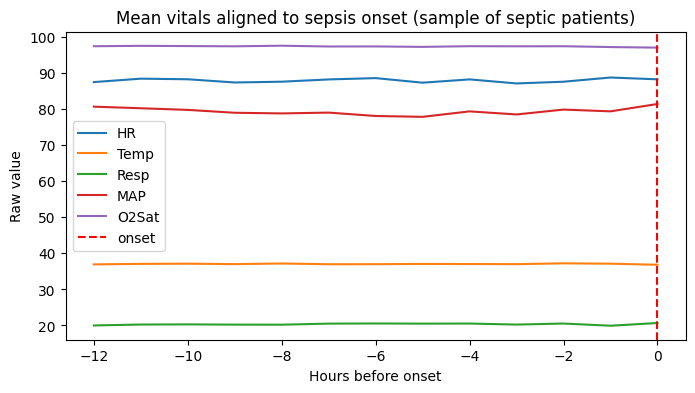

In [2]:
# How long are stays, how much of a 24-hour window is padding, and how do vitals look as sepsis approaches?
meta = np.load(PATHS["sequences"] / "train_meta.npz")
starts = meta["patient_start"]
# length of each stay = how many rows share that start
_, counts = np.unique(starts, return_counts=True)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(counts, bins=40, color="#3b6ea5", edgecolor="white")
ax.set_title("Observed hours per patient (train)")
ax.set_xlabel("Hours")
ax.set_ylabel("Patients")
save_fig(fig, PATHS["figures"] / "04_hours_per_patient.png")
plt.show()

# Padding fraction: patients shorter than WINDOW contribute zeros on the left.
pad_frac = np.maximum(WINDOW - counts, 0) / WINDOW
print("mean fraction of a 24h window that would be padded at the *last* hour of the stay:", pad_frac.mean())
print("patients shorter than 24h:", (counts < WINDOW).mean())

# Average trajectories aligned to onset (hours before first label=1).
raw = pd.read_csv(PATHS["raw"] / "dataset.csv")
schema = json.load(open(PATHS["processed"] / "schema.json"))
pid, hour, target = schema["patient_id"], schema["hour"], schema["target"]
raw = raw.dropna(subset=[pid, target])
raw[pid] = raw[pid].astype(int)
vitals = [c for c in ["HR", "Temp", "Resp", "MAP", "O2Sat"] if c in raw.columns]
ever = raw.groupby(pid)[target].max()
septic = ever[ever == 1].index
# Use a sample of septic patients for a readable average.
rng = np.random.default_rng(SEED)
pick = rng.choice(septic, size=min(250, len(septic)), replace=False)
aligned = {v: [] for v in vitals}
for i in pick:
    g = raw[raw[pid]==i].sort_values(hour)
    if (g[target]==1).any():
        onset = g.loc[g[target]==1, hour].iloc[0]
        g = g.copy()
        g["t"] = g[hour] - onset
        sub = g[(g["t"] >= -12) & (g["t"] <= 0)]
        for v in vitals:
            aligned[v].append(sub.set_index("t")[v])
fig, ax = plt.subplots(figsize=(8, 4))
t_index = np.arange(-12, 1)
for v in vitals:
    mat = pd.concat(aligned[v], axis=1)
    ax.plot(mat.mean(axis=1).reindex(t_index), label=v)
ax.axvline(0, color="red", linestyle="--", label="onset")
ax.set_title("Mean vitals aligned to sepsis onset (sample of septic patients)")
ax.set_xlabel("Hours before onset")
ax.set_ylabel("Raw value")
ax.legend()
save_fig(fig, PATHS["figures"] / "04_onset_aligned_vitals.png")
plt.show()


**What we learned.** Many stays are shorter than 24 hours, so the mask is essential. Vitals often drift in the hours before the label flips — that is the signal the LSTM is hoping to use.


In [3]:
# Load sequence arrays. Train uses the documented patient subsample + negative downsampling; val/test stay natural.
dl = load_sequence_split(PATHS["sequences"], "dl_train")
val = load_sequence_split(PATHS["sequences"], "val")
test = load_sequence_split(PATHS["sequences"], "test")
feat_names = json.load(open(PATHS["processed"] / "sequence_feature_cols.json"))
print("features", len(feat_names), feat_names[:8], "...")

# Downsample validation *only* for the per-epoch monitor so early stopping is fast.
# Threshold selection later uses the full validation set.
rng = np.random.default_rng(SEED)
val_mon_idx = downsample_indices(val["y"], max_neg_per_pos=6.0, seed=SEED)
train_idx = downsample_indices(dl["y"], max_neg_per_pos=8.0, seed=SEED)
print("train windows used", len(train_idx), "pos_rate", dl["y"][train_idx].mean())
print("val monitor windows", len(val_mon_idx), "full val", len(val["y"]))

train_ds = WindowSequenceDataset(dl["X"], dl["y"], dl["patient_start"], dl["patient_id"], dl["hour"], WINDOW, train_idx)
val_mon_ds = WindowSequenceDataset(val["X"], val["y"], val["patient_start"], val["patient_id"], val["hour"], WINDOW, val_mon_idx)
val_ds = WindowSequenceDataset(val["X"], val["y"], val["patient_start"], val["patient_id"], val["hour"], WINDOW)
test_ds = WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW)

n_pos = float((dl["y"][train_idx] == 1).sum())
n_neg = float((dl["y"][train_idx] == 0).sum())
pos_weight = n_neg / max(n_pos, 1.0)
print("BCE pos_weight", round(pos_weight, 3))
n_features = dl["X"].shape[1]
print("n_features", n_features)


features 72 ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'BaseExcess'] ...
train windows used 30159 pos_rate 0.11111111
val monitor windows 12481 full val 82478
BCE pos_weight 8.0
n_features 72


## Architecture: 2-layer LSTM → dropout → linear logit


In [4]:
# hidden=64 keeps CPU training reasonable. Each layer comment lives in src/torch_models.py as well.
model = LSTMClassifier(n_features=n_features, hidden=64, dropout=0.3)
print(model)
print("parameters", count_parameters(model))


LSTMClassifier(
  (lstm): LSTM(72, 64, num_layers=2, batch_first=True, dropout=0.3)
  (drop): Dropout(p=0.3, inplace=False)
  (head): Linear(in_features=64, out_features=1, bias=True)
)
parameters 68673


## Train with Adam, pos_weight, grad clip, early stopping


epoch 01  train_loss=0.9845  val_loss=1.4308  val_pr_auc=0.3732
epoch 02  train_loss=0.7747  val_loss=1.8128  val_pr_auc=0.3258
epoch 03  train_loss=0.6688  val_loss=2.3976  val_pr_auc=0.3270
epoch 04  train_loss=0.6005  val_loss=3.0647  val_pr_auc=0.3001
Early stopping at epoch 4 (best val PR-AUC=0.3732)


/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "id": "7736443a",


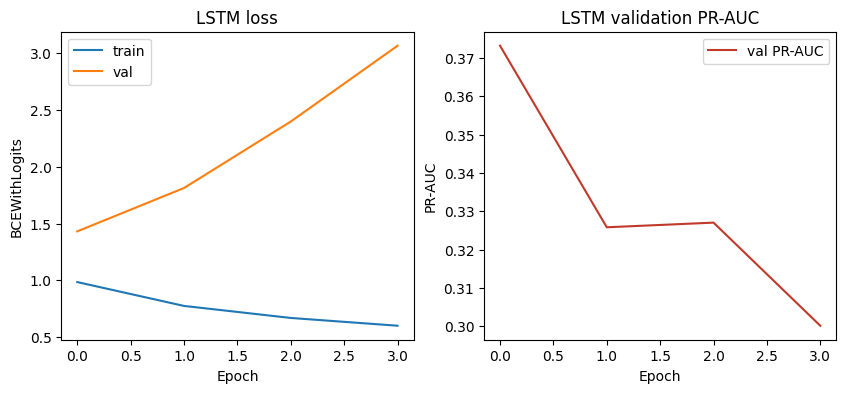

In [5]:
# Early stopping watches validation PR-AUC (not accuracy). Best weights are restored at the end.
history = train_sequence_model(
    model, train_ds, val_mon_ds, DEVICE,
    pos_weight=pos_weight, epochs=10, patience=3, lr=1e-3, batch_size=128,
    ckpt_path=PATHS["models"] / "lstm_best.pt",
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("LSTM loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCEWithLogits")
axes[0].legend()
axes[1].plot(history["val_pr_auc"], label="val PR-AUC", color="#c0392b")
axes[1].set_title("LSTM validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()
save_fig(fig, PATHS["figures"] / "04_lstm_curves.png")
plt.show()


## Threshold, test evaluation, save


threshold 0.9 val F1 0.178 val PR-AUC 0.0888
{'roc_auc': 0.7262, 'pr_auc': 0.0826, 'precision': 0.1428, 'recall': 0.1877, 'f1': 0.1622, 'specificity': 0.9748, 'accuracy': 0.9575, 'brier': 0.1583, 'threshold': 0.9, 'tp': 333, 'fp': 1999, 'tn': 77210, 'fn': 1441, 'n': 80983, 'n_positive': 1774}
early detection {'n_sepsis_patients': 186, 'pct_detected': 23.655913978494624, 'pct_detected_6h_before': 16.129032258064516, 'edt_mean_hours': 36.70454545454545, 'edt_median_hours': 21.5, 'false_alarms_per_patient_day': 0.6056887474908155, 'n_detected': 44}
saved /Users/shaikniyaz/projects/CSET343_project/models/lstm.pt


/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "cell_type": "code",
/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "id": "7736443a",


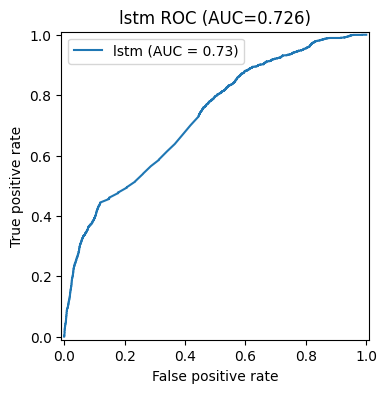

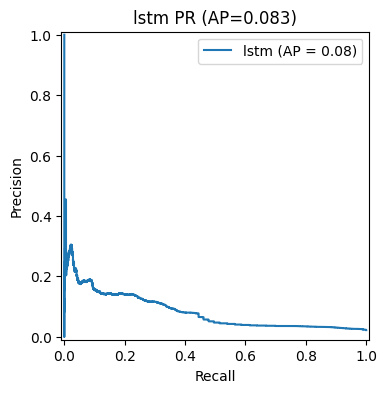

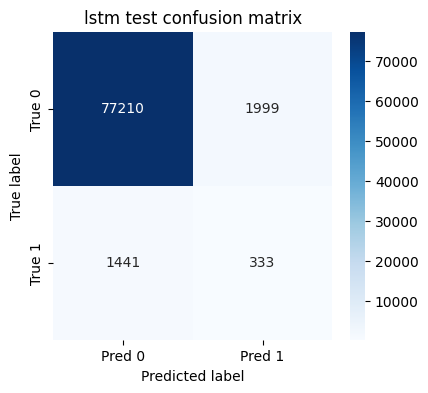

In [6]:
# Freeze the F1-max threshold on FULL validation, then score test patients only once.
p_va = predict_torch_model(model, val_ds, DEVICE, batch_size=256)
thr, val_m = choose_threshold_max_f1(val["y"], p_va)
print("threshold", round(thr, 4), "val F1", round(val_m["f1"], 4), "val PR-AUC", round(val_m["pr_auc"], 4))

t1 = time.time()
p_te = predict_torch_model(model, test_ds, DEVICE, batch_size=256)
infer_seconds = time.time() - t1
metrics = classification_metrics(test["y"], p_te, thr)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()})

pred_path = PATHS["results"] / "predictions_lstm.csv"
save_predictions(test["patient_id"], test["hour"], test["y"], p_te, pred_path)
edt, _ = early_detection_metrics(pd.read_csv(pred_path), "patient_id", "hour", threshold=thr)
print("early detection", edt)

plot_roc_pr(test["y"], p_te, "lstm", PATHS["figures"] / "04_lstm_roc.png", PATHS["figures"] / "04_lstm_pr.png")
plt.show()
plot_confusion_heatmap(metrics, "lstm test confusion matrix", PATHS["figures"] / "04_lstm_cm.png")
plt.show()

ckpt = PATHS["models"] / "lstm.pt"
torch.save({"state_dict": model.state_dict(), "threshold": thr, "n_features": n_features, "window": WINDOW}, ckpt)
extra = dict(
    train_seconds=history["train_seconds"], infer_seconds=infer_seconds,
    n_params=count_parameters(model), model_mb=file_size_mb(ckpt),
    **{f"edt_{k}": v for k, v in edt.items() if k != "n_sepsis_patients"},
    n_sepsis_patients=edt["n_sepsis_patients"],
)
save_metrics_table(metrics_to_row("lstm", metrics, extra), PATHS["tables"] / "metrics_lstm.csv")
print("saved", ckpt)


## Explainability


baseline PR-AUC on SHAP/permutation sample: 0.1245
         feature  pr_auc_drop
          ICULOS     0.079460
            SaO2     0.021350
           PaCO2     0.017010
       Potassium     0.016441
              HR     0.013752
       Platelets     0.013729
        Chloride     0.010726
 Bilirubin_total     0.010411
   Resp_measured     0.010256
     HospAdmTime     0.009437
Glucose_measured     0.009174
         Calcium     0.006961
SHAP GradientExplainer not used (unstable or failed). Fallback = permutation importance.
reason: IndexError too many indices for tensor of dimension 1


/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "**Outputs.** `models/lstm.pt`, `results/predictions_lstm.csv`, `results/tables/metrics_lstm.csv`.\n"
/Users/shaikniyaz/projects/CSET343_project/notebooks/04_model_lstm.ipynb:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "# Shared deep-learning setup: frozen splits, GPU if available, one global seed.\n",


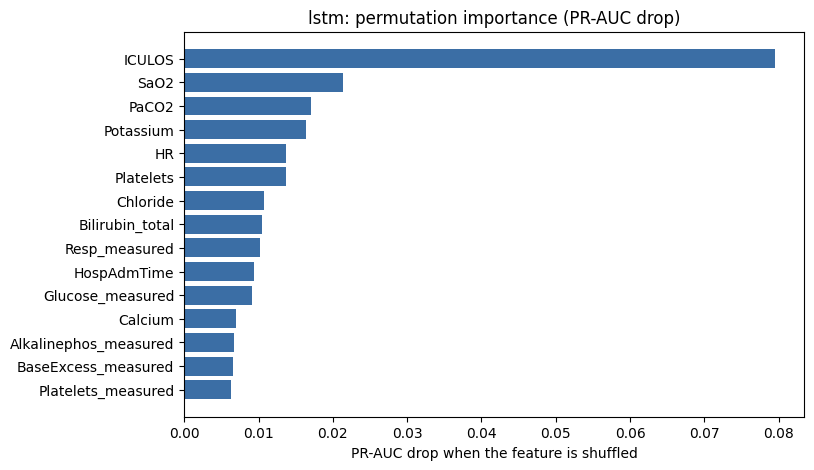

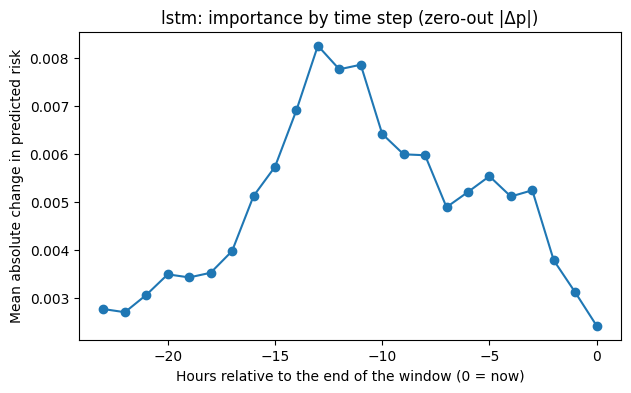

In [7]:
# Explainability: try a small SHAP GradientExplainer; if it fails or looks unstable, fall back to permutation importance.
# We also measure which hours in the 24-hour window move the prediction the most.
from sklearn.metrics import average_precision_score

imp_df, base_ap = permutation_importance_torch(model, test_ds, DEVICE, feat_names, n_samples=350, seed=SEED)
print("baseline PR-AUC on SHAP/permutation sample:", round(base_ap, 4))
print(imp_df.head(12).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
top = imp_df.head(15).iloc[::-1]
ax.barh(top["feature"], top["pr_auc_drop"], color="#3b6ea5")
ax.set_title("lstm: permutation importance (PR-AUC drop)")
ax.set_xlabel("PR-AUC drop when the feature is shuffled")
save_fig(fig, PATHS["figures"] / "04_lstm_perm_importance.png")
plt.show()

impact = time_step_importance_torch(model, test_ds, DEVICE, n_samples=350, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
hours_before = np.arange(-WINDOW + 1, 1)
ax.plot(hours_before, impact, marker="o")
ax.set_title("lstm: importance by time step (zero-out |Δp|)")
ax.set_xlabel("Hours relative to the end of the window (0 = now)")
ax.set_ylabel("Mean absolute change in predicted risk")
save_fig(fig, PATHS["figures"] / "04_lstm_time_importance.png")
plt.show()

# Optional SHAP on a tiny batch; skip cleanly if the explainer errors.
try:
    import shap
    from torch.utils.data import DataLoader
    bg_n = 32
    ex_n = 48
    bg_loader = DataLoader(WindowSequenceDataset(dl["X"], dl["y"], dl["patient_start"], dl["patient_id"], dl["hour"], WINDOW, train_idx[:bg_n]), batch_size=bg_n)
    ex_loader = DataLoader(WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW, np.arange(ex_n)), batch_size=ex_n)
    bg_seq, bg_mask, _, _ = next(iter(bg_loader))
    ex_seq, ex_mask, _, _ = next(iter(ex_loader))
    # Flatten time*feature so GradientExplainer sees a 2D tensor, then wrap the model.
    class FlatWrap(torch.nn.Module):
        def __init__(self, m, t, f, mask):
            super().__init__()
            self.m, self.t, self.f, self.mask = m, t, f, mask
        def forward(self, z):
            x = z.view(-1, self.t, self.f)
            return self.m(x, self.mask.to(z.device)[:x.size(0)] if self.mask.size(0)==x.size(0) else self.mask[:1].repeat(x.size(0),1))
    model.eval()
    wrap = FlatWrap(model, WINDOW, n_features, ex_mask.to(DEVICE)).to(DEVICE)
    explainer = shap.GradientExplainer(wrap, bg_seq.to(DEVICE).reshape(bg_n, -1))
    sv = explainer.shap_values(ex_seq.to(DEVICE).reshape(ex_n, -1))
    sv = np.array(sv).reshape(ex_n, WINDOW, n_features)
    mean_abs = np.abs(sv).mean(axis=(0, 1))
    order = np.argsort(mean_abs)[-15:]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh([feat_names[i] for i in order], mean_abs[order], color="#3b6ea5")
    ax.set_title("lstm: mean |SHAP| aggregated over time")
    ax.set_xlabel("mean |SHAP|")
    save_fig(fig, PATHS["figures"] / "04_lstm_shap_bar.png")
    plt.show()
    print("SHAP GradientExplainer succeeded on a small sample.")
except Exception as e:
    print("SHAP GradientExplainer not used (unstable or failed). Fallback = permutation importance.")
    print("reason:", type(e).__name__, str(e)[:300])


### Notebook 04 summary


In [8]:
print(pd.read_csv(PATHS["tables"] / "metrics_lstm.csv").T)
print("Done with notebook 04.")


                                          0
model                                  lstm
roc_auc                             0.72623
pr_auc                             0.082571
precision                          0.142796
recall                             0.187711
f1                                 0.162202
specificity                        0.974763
accuracy                           0.957522
brier                               0.15826
threshold                               0.9
tp                                      333
fp                                     1999
tn                                    77210
fn                                     1441
n                                     80983
n_positive                             1774
train_seconds                     11.925677
infer_seconds                      2.500615
n_params                              68673
model_mb                              0.265
edt_pct_detected                  23.655914
edt_pct_detected_6h_before      